# Lab 7 · Noise channels and the Bloch ball

**Levels 5–6 · Quantum information → Quantum causal models** · Prerequisite lessons: L5-05 (Density operators and reduced states), L5-06 (Quantum channels and complete positivity), L5-10 (Noise, encoding, and error correction), L6-02 (Channels in the Choi representation).

**What you'll learn**

- How to write a quantum channel with Kraus operators. What the completeness condition $\sum_k K_k^\dagger K_k=I$ guarantees.
- How depolarizing, dephasing, and amplitude-damping noise squash and shift the Bloch ball.
- How purity decays under repeated noise, and why amplitude damping behaves differently.
- What the Choi matrix is, and why its positivity is the test for *complete* positivity (CP).

Channels, Kraus operators, and the Choi representation are standard material [@watrous; @preskill].

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/07-noise-channels.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)
CHANNELS = {"depolarizing": s.depolarizing_kraus, "dephasing": s.dephasing_kraus,
            "amplitude damping": s.amplitude_damping_kraus}

## 1 · Kraus operators and trace preservation

A channel acts as $\mathcal E(\rho)=\sum_k K_k\rho K_k^\dagger$. It preserves the trace for every $\rho$ exactly when $\sum_k K_k^\dagger K_k=I$. The engine has three channels:

| channel | strength | Kraus operators |
|----|----|----|
| depolarizing | $p$ | $\sqrt{1-3p/4}\,I,\ \sqrt{p/4}\,X,\ \sqrt{p/4}\,Y,\ \sqrt{p/4}\,Z$ |
| dephasing | $p$ | $\sqrt{1-p/2}\,I,\ \sqrt{p/2}\,Z$ |
| amplitude damping | $\gamma$ | $K_0,\ K_1$ below |

$$
K_0=\begin{pmatrix}1&0\\0&\sqrt{1-\gamma}\end{pmatrix},\qquad K_1=\begin{pmatrix}0&\sqrt\gamma\\0&0\end{pmatrix}.
$$

:::{note} Predict
Which of the three channels has a fixed point that is *not* the maximally mixed state $I/2$?
:::

In [3]:
for name, kraus in CHANNELS.items():
    for p in np.linspace(0, 1, 11):
        K = kraus(float(p))
        assert s.is_cptp(K)
        assert np.allclose(sum(k.conj().T @ k for k in K), np.eye(2))
    print(f"{name:18s}: completeness holds for 11 strengths in [0, 1]")

mixed = np.eye(2) / 2
for name, kraus in CHANNELS.items():
    out = s.apply_kraus(mixed, kraus(0.6))
    print(f"{name:18s}: E(I/2) Bloch vector = {s.bloch(out)}")
ad_fixed = s.apply_kraus(s.dm(s.KET0), s.amplitude_damping_kraus(0.6))
assert np.allclose(ad_fixed, s.dm(s.KET0))                       # |0> is the fixed point of amplitude damping
assert not np.allclose(s.apply_kraus(mixed, s.amplitude_damping_kraus(0.6)), mixed)

depolarizing      : completeness holds for 11 strengths in [0, 1]
dephasing         : completeness holds for 11 strengths in [0, 1]
amplitude damping : completeness holds for 11 strengths in [0, 1]
depolarizing      : E(I/2) Bloch vector = [0. 0. 0.]
dephasing         : E(I/2) Bloch vector = [0. 0. 0.]
amplitude damping : E(I/2) Bloch vector = [0.  0.  0.6]


**Explain.** Depolarizing and dephasing are *unital*: they leave $I/2$ unchanged. Amplitude damping is not unital. It models energy loss. It pulls every state towards $|0\rangle$, and that state is its fixed point.

## 2 · How noise deforms the Bloch ball

Every qubit channel acts on Bloch vectors as an affine map $\vec r\mapsto M\vec r+\vec c$. For these three channels:

- depolarizing: $\vec r\mapsto(1-p)\,\vec r$ (uniform shrink);
- dephasing: $(x,y,z)\mapsto\big((1-p)x,\ (1-p)y,\ z\big)$ (squash towards the $z$ axis);
- amplitude damping: $(x,y,z)\mapsto\big(\sqrt{1-\gamma}\,x,\ \sqrt{1-\gamma}\,y,\ \gamma+(1-\gamma)z\big)$ (shrink *and* shift towards the north pole).

The code applies the Kraus operators to every point on the sphere and checks each formula. In the figure, pick the channel with the buttons and set the strength with the slider. The faint grey wireframe is the original sphere.

In [4]:
th, ph = np.mgrid[0:np.pi:16j, 0:2 * np.pi:26j]
pure = [[s.dm(s.ket(float(t), float(f))) for t, f in zip(rt, rf)] for rt, rf in zip(th, ph)]
R0 = np.array([[s.bloch(r) for r in row] for row in pure])            # shape (16, 26, 3)

def image(name, p):
    K = CHANNELS[name](p)
    return np.array([[s.bloch(s.apply_kraus(r, K)) for r in row] for row in pure])

def closed_form(name, p, R):
    x, y, z = R[..., 0], R[..., 1], R[..., 2]
    if name == "depolarizing":
        return np.stack([(1 - p) * x, (1 - p) * y, (1 - p) * z], -1)
    if name == "dephasing":
        return np.stack([(1 - p) * x, (1 - p) * y, z], -1)
    return np.stack([math.sqrt(1 - p) * x, math.sqrt(1 - p) * y, p + (1 - p) * z], -1)

strengths = np.round(np.linspace(0, 1, 11), 2)
imgs = {(n, p): image(n, float(p)) for n in CHANNELS for p in strengths}
for (n, p), im in imgs.items():
    assert np.allclose(im, closed_form(n, float(p), R0), atol=1e-12)
print("Kraus action matches the closed-form Bloch maps at", len(imgs), "(channel, strength) pairs.")

names = list(CHANNELS)
colors = {"depolarizing": "Blues", "dephasing": "Greens", "amplitude damping": "Oranges"}
p_init = 4  # strength 0.4
traces = [go.Scatter3d(x=np.r_[R0[:, :, 0].ravel(), None], y=np.r_[R0[:, :, 1].ravel(), None],
                       z=np.r_[R0[:, :, 2].ravel(), None], mode="markers", marker=dict(size=1.5, color="lightgray"),
                       hoverinfo="skip", name="original sphere")]
for k, n in enumerate(names):
    im = imgs[(n, strengths[p_init])]
    traces.append(go.Surface(x=im[..., 0], y=im[..., 1], z=im[..., 2], colorscale=colors[n], showscale=False,
                             opacity=0.85, visible=(k == 0), name=n, hovertemplate="x=%{x:.2f}<br>y=%{y:.2f}<br>z=%{z:.2f}"))
fig = go.Figure(traces)
idx = [1, 2, 3]
steps = []
for p in strengths:
    ims = [imgs[(n, p)] for n in names]
    steps.append(dict(method="restyle", label=f"{p:.1f}",
                      args=[{"x": [im[..., 0].tolist() for im in ims], "y": [im[..., 1].tolist() for im in ims],
                             "z": [im[..., 2].tolist() for im in ims]}, idx]))
buttons = [dict(label=n, method="restyle", args=[{"visible": [j == k for j in range(3)]}, idx]) for k, n in enumerate(names)]
fig.update_layout(height=640, title="Image of the Bloch sphere under a noise channel", margin=dict(l=0, r=0, t=60, b=0),
                  scene=dict(aspectmode="cube", xaxis=dict(range=[-1.1, 1.1]), yaxis=dict(range=[-1.1, 1.1]),
                             zaxis=dict(range=[-1.1, 1.1])),
                  updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.08, xanchor="left", buttons=buttons)],
                  sliders=[dict(active=p_init, currentvalue=dict(prefix="strength p (or γ) = "), steps=steps)])
show(fig)

Kraus action matches the closed-form Bloch maps at

 33 (channel, strength) pairs.


**Explain.** Depolarizing shrinks the ball uniformly towards the centre. Dephasing flattens it into a cigar along $z$. Populations in the $Z$ basis survive; coherences do not. Amplitude damping shrinks the ball *and* moves it up. At strength 1 the whole ball collapses onto the north pole $|0\rangle$.

## 3 · Purity decay under repeated noise

Apply the same channel $n$ times to the pure state $|+\rangle$. Under depolarizing and dephasing, the Bloch vector shrinks geometrically, so the purity is $\tfrac{1}{2}\big(1+(1-p)^{2n}\big)$. Under amplitude damping, let $a=(1-\gamma)^n$. The Bloch vector is then $(\sqrt a,\,0,\,1-a)$ and the purity is $\tfrac{1}{2}\big(1+a+(1-a)^2\big)$.

:::{note} Predict
Under repeated amplitude damping, does the purity of $|+\rangle$ keep falling?
:::

In [5]:
plus = s.dm(np.array([1, 1]) / math.sqrt(2))
nmax = 25
ns = np.arange(nmax + 1)

def purity_trace(name, p):
    K, rho, out = CHANNELS[name](p), plus.copy(), []
    for _ in ns:
        out.append(s.purity(rho))
        rho = s.apply_kraus(rho, K)
    return np.array(out)

ps = np.round(np.linspace(0.05, 0.5, 10), 2)
P = {(n, p): purity_trace(n, float(p)) for n in names for p in ps}
for p in ps:
    a = (1 - p) ** ns
    assert np.allclose(P[("depolarizing", p)], 0.5 * (1 + (1 - p) ** (2 * ns)))
    assert np.allclose(P[("dephasing", p)], 0.5 * (1 + (1 - p) ** (2 * ns)))
    assert np.allclose(P[("amplitude damping", p)], 0.5 * (1 + a + (1 - a) ** 2))
    assert P[("amplitude damping", p)].min() >= 7 / 8 - 1e-12        # min of 1 - a + a^2 is 3/4 at a = 1/2
ad = P[("amplitude damping", 0.3)]
print(f"amplitude damping, gamma = 0.3: purity falls to {ad.min():.4f} at n = {ad.argmin()}, then rises to {ad[-1]:.4f} at n = {nmax}")
assert ad.argmin() > 0 and ad[-1] > ad.min()

p0i = 2
fig = go.Figure([go.Scatter(x=ns, y=P[(n, ps[p0i])], mode="lines+markers", name=n) for n in names])
steps = [dict(method="restyle", label=f"{p:.2f}", args=[{"y": [P[(n, p)] for n in names]}, [0, 1, 2]]) for p in ps]
fig.add_hline(y=0.5, line_dash="dot", annotation_text="maximally mixed")
fig.update_layout(height=470, title="Purity of |+⟩ after n applications of the channel", xaxis_title="number of applications n",
                  yaxis_title="purity Tr ρ²", yaxis_range=[0.45, 1.02],
                  sliders=[dict(active=p0i, currentvalue=dict(prefix="strength = "), pad=dict(t=50), steps=steps)])
show(fig)

amplitude damping, gamma = 0.3: purity falls to 0.8750 at n = 2, then rises to 0.9999 at n = 25


**Explain.** For the unital channels, purity falls monotonically to $1/2$. For amplitude damping it first falls, as coherence is lost, but never below $7/8$ for this input. Then it *rises* back to 1, because the channel drives the state to the pure fixed point $|0\rangle$. Purity loss and "noise" are not the same thing.

## 4 · The Choi matrix and complete positivity

A map must stay valid when it acts on *part* of a larger system. That property is called complete positivity. The Choi matrix

$$
J(\mathcal E)=\sum_{i,j}|i\rangle\langle j|\otimes\mathcal E(|i\rangle\langle j|)
$$

turns the question into linear algebra. $\mathcal E$ is CP if and only if $J\ge0$, and trace preserving if and only if $\operatorname{Tr}_{\text{out}}J=I$. A map with both properties is CPTP.

The transpose map $\rho\mapsto\rho^{\top}$ is the classic warning. It maps every single-qubit state to a valid state, so it is *positive*. It is not completely positive.

:::{note} Predict
What happens if you apply the transpose to *one half* of the Bell state $|\Phi^+\rangle$?
:::

depolarizing      : Choi eigenvalues [0.25 0.25 0.25 1.25]
dephasing         : Choi eigenvalues [0.  0.  0.5 1.5]
amplitude damping : Choi eigenvalues [0.  0.  0.5 1.5]
transpose map     : Choi eigenvalues [-1.  1.  1.  1.]
eigenvalues after transposing half of |Phi+>: [-0.5  0.5  0.5  0.5]


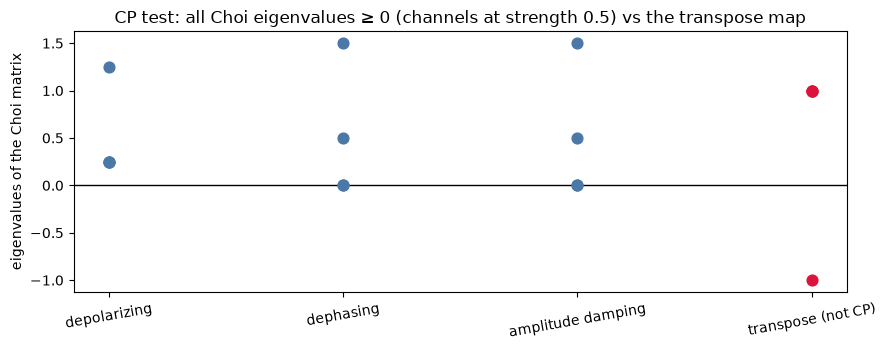

In [6]:
def ptrace_out(J, d=2):
    return np.einsum("ijkj->ik", J.reshape(d, d, d, d))

eigs = {}
for n in names:
    J = s.choi(CHANNELS[n](0.5))
    ev = np.linalg.eigvalsh(J)
    eigs[n] = ev
    assert ev.min() > -1e-12 and np.allclose(ptrace_out(J), np.eye(2))
    print(f"{n:18s}: Choi eigenvalues {np.round(ev, 4)}")

# transpose map: its Choi matrix is the SWAP operator
J_T = sum(np.kron(np.outer(np.eye(2)[i], np.eye(2)[j]), np.outer(np.eye(2)[i], np.eye(2)[j]).T) for i in range(2) for j in range(2))
eigs["transpose (not CP)"] = np.linalg.eigvalsh(J_T)
print("transpose map     : Choi eigenvalues", np.round(eigs["transpose (not CP)"], 4))
assert abs(eigs["transpose (not CP)"].min() + 1) < 1e-12
# positive on single-qubit states...
g = np.random.default_rng(0)
for _ in range(100):
    rho = s.dm(s.ket(*g.uniform(0, math.pi, 2)))
    assert s.is_density_matrix(rho.T)
# ...but not on half of a Bell state
phi = s.dm(s.bell_state("phi+"))
half_T = phi.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)
print("eigenvalues after transposing half of |Phi+>:", np.round(np.linalg.eigvalsh(half_T), 4))
assert np.linalg.eigvalsh(half_T).min() < -0.49

fig, ax = plt.subplots(figsize=(9, 3.6))
labels = list(eigs)
for k, lab in enumerate(labels):
    ax.scatter([k] * 4, eigs[lab], s=60, color="crimson" if eigs[lab].min() < 0 else "#4c78a8", zorder=3)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(len(labels)), labels, rotation=10)
ax.set_ylabel("eigenvalues of the Choi matrix")
ax.set_title("CP test: all Choi eigenvalues ≥ 0 (channels at strength 0.5) vs the transpose map")
plt.tight_layout(); plt.show()

**Explain.** All three channels have positive semidefinite Choi matrices with $\operatorname{Tr}_{\text{out}}J=I$, so they are CPTP. The transpose has a Choi eigenvalue $-1$. Applied to half of $|\Phi^+\rangle$, it outputs an operator with eigenvalue $-1/2$. That is not a state. A physical noise process can never do this.

## Going deeper: from Choi back to Kraus

Diagonalise $J=\sum_k \lambda_k |v_k\rangle\langle v_k|$ with $\lambda_k\ge0$. Take each $\sqrt{\lambda_k}\,|v_k\rangle$, a vector in $\mathbb C^{d}\otimes\mathbb C^{d}$, and reshape it into a $d\times d$ matrix. The result is a valid set of Kraus operators. Kraus operators are not unique, but the channel is. The number of nonzero $\lambda_k$ (the Choi rank) is the minimum number of Kraus operators. The next cell rebuilds each channel from its Choi matrix and checks that the action is identical.

In [7]:
def kraus_from_choi(J, d=2, tol=1e-12):
    lam, V = np.linalg.eigh(J)
    # With J = sum_ij |i><j| (x) E(|i><j|), the vector index is (in, out); K[out, in] = sqrt(lam) v[in, out].
    return [math.sqrt(l) * V[:, k].reshape(d, d).T for k, l in enumerate(lam) if l > tol]

g = np.random.default_rng(4)
for n in names:
    for p in (0.2, 0.7):
        K = CHANNELS[n](p)
        K2 = kraus_from_choi(s.choi(K))
        assert s.is_cptp(K2)
        for _ in range(20):
            G = g.normal(size=(2, 2)) + 1j * g.normal(size=(2, 2)); rho = G @ G.conj().T; rho /= np.trace(rho)
            assert np.allclose(s.apply_kraus(rho, K), s.apply_kraus(rho, K2), atol=1e-12)
        print(f"{n:18s} p={p}: Choi rank {len(K2)} (engine uses {len(K)} Kraus operators)")

depolarizing       p=0.2: Choi rank 4 (engine uses 4 Kraus operators)
depolarizing       p=0.7: Choi rank 4 (engine uses 4 Kraus operators)
dephasing          p=0.2: Choi rank 2 (engine uses 2 Kraus operators)
dephasing          p=0.7: Choi rank 2 (engine uses 2 Kraus operators)
amplitude damping  p=0.2: Choi rank 2 (engine uses 2 Kraus operators)
amplitude damping  p=0.7: Choi rank 2 (engine uses 2 Kraus operators)


## Exercises

:::{admonition} Exercise: :label: lab07-ex1
:class: tip
Apply depolarizing noise with $p=0.3$ twice. Which single depolarizing strength $p'$ has the same effect?
:::

:::{dropdown} Solution
Each application multiplies the Bloch vector by $1-p$. Twice gives $(0.7)^2=0.49=1-p'$, so $p'=0.51$.
:::

:::{admonition} Exercise: :label: lab07-ex2
:class: tip
Show that the maximally mixed state is *not* a fixed point of amplitude damping with $\gamma=0.6$, and find where it goes.
:::

:::{dropdown} Solution
$\vec r=0$ maps to $(0,0,\gamma)=(0,0,0.6)$. The output is $\tfrac12(I+0.6Z)=\mathrm{diag}(0.8,0.2)$.
:::

:::{admonition} Exercise: :label: lab07-ex3
:class: tip
Fully dephase ($p=1$) the state with Bloch vector $(0.6, 0, 0.8)$. What is left, and what is its purity?
:::

:::{dropdown} Solution
$x$ and $y$ are erased and $z$ survives: $(0,0,0.8)$. Purity $=(1+0.64)/2=0.82$.
:::

## Check yourself

In [8]:
g = np.random.default_rng(9)
for _ in range(20):
    G = g.normal(size=(2, 2)) + 1j * g.normal(size=(2, 2)); rho = G @ G.conj().T; rho /= np.trace(rho)
    twice = s.apply_kraus(s.apply_kraus(rho, s.depolarizing_kraus(0.3)), s.depolarizing_kraus(0.3))
    assert np.allclose(twice, s.apply_kraus(rho, s.depolarizing_kraus(0.51)))
out = s.apply_kraus(np.eye(2) / 2, s.amplitude_damping_kraus(0.6))
assert np.allclose(out, np.diag([0.8, 0.2])) and np.allclose(s.bloch(out), [0, 0, 0.6])
rho = 0.5 * (s.I2 + 0.6 * s.X + 0.8 * s.Z)
deph = s.apply_kraus(rho, s.dephasing_kraus(1.0))
assert np.allclose(s.bloch(deph), [0, 0, 0.8]) and abs(s.purity(deph) - 0.82) < 1e-12
print("All checks passed.")

All checks passed.


## Limits of this model

The noise is memoryless (Markovian): each application is independent. Real devices show drift and correlated errors across time and qubits.

The model covers one qubit. Multi-qubit noise includes correlated Kraus operators that these single-qubit channels cannot express.

The parameters are idealized. We chose the strengths $p$ and $\gamma$ by hand; they are not fitted to any device.

There is no error correction. We only describe the damage. Lesson L5-10 discusses how encoding can protect information.